In [1]:

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import joblib

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load Adult Income Dataset

adult = fetch_openml(
    name="adult",
    version=2,
    as_frame=True
)

X = adult.data.copy()
y = adult.target.copy()

# Clean categorical values
for col in X.select_dtypes(include=["object", "category"]).columns:
    X[col] = X[col].apply(
        lambda v: v.strip() if isinstance(v, str) else v
    )
    X[col] = X[col].replace("?", np.nan)

# Clean target labels
y = y.astype(str).str.strip()
y = y.str.replace(r"\.$", "", regex=True)

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)

print("\nFirst five rows:")
display(X.head())

print("\nTarget values:")
print(y.value_counts())


Dataset loaded successfully!
Dataset shape: (48842, 14)

First five rows:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States



Target values:
class
<=50K    37155
>50K     11687
Name: count, dtype: int64


In [3]:

# Check missing values

print("Missing values in each column:")

missing_values = X.isnull().sum()

print(missing_values)

print("\nTotal missing values:")
print(missing_values.sum())


Missing values in each column:
age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
dtype: int64

Total missing values:
6465


In [4]:

# Split dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nData successfully split!")


Training data: (39073, 14)
Testing data: (9769, 14)

Data successfully split!


In [5]:

# Identify numerical and categorical columns

numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical Features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [6]:

# Numerical preprocessing pipeline

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing pipeline

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipelines created successfully!")


Preprocessing pipelines created successfully!


In [7]:

# Create complete machine learning pipeline

pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train the model

pipeline.fit(X_train, y_train)

print("Machine Learning Pipeline trained successfully!")


Machine Learning Pipeline trained successfully!


In [8]:

# Make predictions

y_pred = pipeline.predict(X_test)

# Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Model Accuracy: 85.94 %

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      7431
        >50K       0.74      0.63      0.68      2338

    accuracy                           0.86      9769
   macro avg       0.82      0.78      0.80      9769
weighted avg       0.85      0.86      0.86      9769



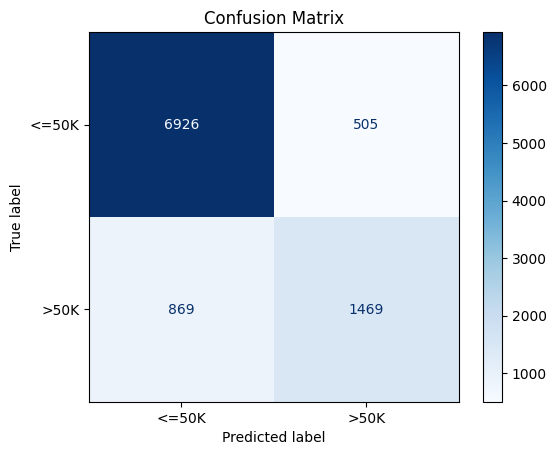

In [9]:

# Display confusion matrix

cm = confusion_matrix(y_test, y_pred)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=pipeline.classes_
)

display_matrix.plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.show()


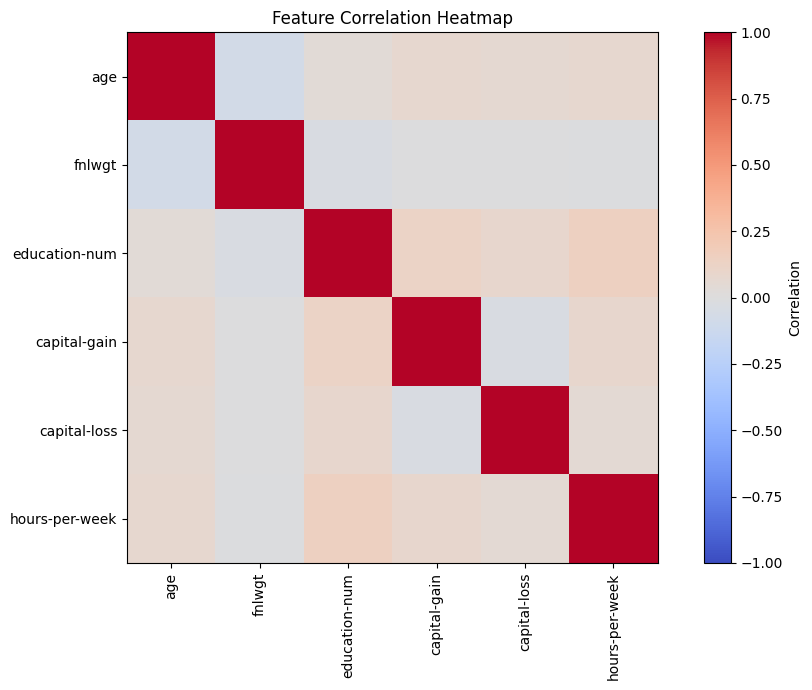

Correlation analysis completed!


In [10]:

# Correlation analysis using training data only

correlation = X_train[numerical_features].corr()

plt.figure(figsize=(10, 7))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(numerical_features)),
    numerical_features,
    rotation=90
)

plt.yticks(
    range(len(numerical_features)),
    numerical_features
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Correlation analysis completed!")


Top 15 Important Features:


,Feature,Importance
0,num__age,0.152410
1,num__fnlwgt,0.144959
32,cat__marital-status_Married-civ-spouse,0.081891
5,num__hours-per-week,0.080368
3,num__capital-gain,0.066524
2,num__education-num,0.061615
51,cat__relationship_Husband,0.061429
34,cat__marital-status_Never-married,0.045034
4,num__capital-loss,0.023233
54,cat__relationship_Own-child,0.015805


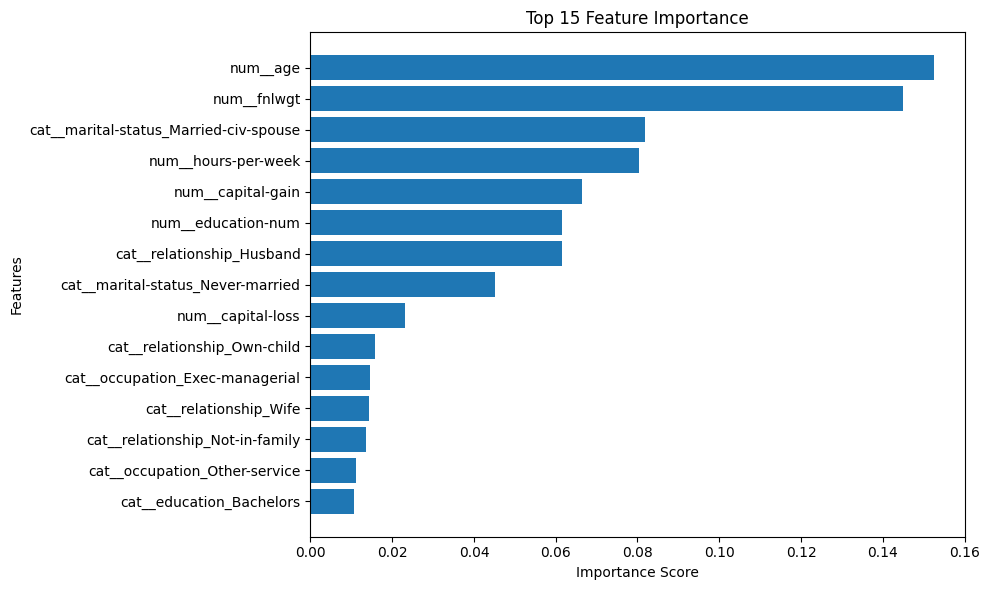

In [11]:

# Get feature importance from Random Forest

feature_names = (
    pipeline.named_steps["preprocessing"]
    .get_feature_names_out()
)

importance = pipeline.named_steps["model"].feature_importances_

# Create feature importance dataframe

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort features by importance

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")

display(importance_df.head(15))

# Plot feature importance

top_features = importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.title("Top 15 Feature Importance")

plt.tight_layout()
plt.show()


In [12]:

# Save the complete trained pipeline

joblib.dump(
    pipeline,
    "feature_engineering_pipeline.pkl"
)

print("Pipeline saved successfully!")

# Test loading the saved pipeline

loaded_pipeline = joblib.load(
    "feature_engineering_pipeline.pkl"
)

sample_predictions = loaded_pipeline.predict(
    X_test.head(5)
)

print("\nSample Predictions:")
print(sample_predictions)


Pipeline saved successfully!

Sample Predictions:
['<=50K' '<=50K' '>50K' '<=50K' '>50K']


In [13]:

# Final project summary

print("=" * 50)
print("FEATURE ENGINEERING PROJECT COMPLETED")
print("=" * 50)

print("Dataset: Adult Income Dataset")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nCompleted Tasks:")
print("1. Dataset Loading")
print("2. Missing Value Analysis")
print("3. Train/Test Splitting")
print("4. Numerical Feature Scaling")
print("5. Categorical One-Hot Encoding")
print("6. Scikit-Learn Pipeline")
print("7. Correlation Analysis")
print("8. Feature Importance Analysis")
print("9. Pipeline Saving")

print("\nPROJECT COMPLETED SUCCESSFULLY!")


FEATURE ENGINEERING PROJECT COMPLETED
Dataset: Adult Income Dataset
Training Samples: 39073
Testing Samples: 9769
Accuracy: 85.94 %

Completed Tasks:
1. Dataset Loading
2. Missing Value Analysis
3. Train/Test Splitting
4. Numerical Feature Scaling
5. Categorical One-Hot Encoding
6. Scikit-Learn Pipeline
7. Correlation Analysis
8. Feature Importance Analysis
9. Pipeline Saving

PROJECT COMPLETED SUCCESSFULLY!
